In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
sns.set_theme(style="whitegrid")
matches = pd.read_csv("dataset_1.csv", parse_dates=["date"])
features = [
    "team_goals_for_5", "team_goals_against_5",
    "opponent_goals_for_5", "opponent_goals_against_5",
    "team_prior_matches", "opponent_prior_matches",
    "team_prior_points_per_game", "opponent_prior_points_per_game",
]
assert len(features) == 8 and len(set(features)) == 8

In [3]:
required = ["match_id", "date", "team_a", "team_b", "goals_a", "goals_b"]
assert set(required).issubset(matches.columns), f"Missing columns: {set(required) - set(matches.columns)}"
assert len(matches) == 104, f"Expected 104 matches, found {len(matches)}"
assert matches["match_id"].is_unique, "Each match_id must identify one match in this 104-row CSV"
assert not matches[required].isna().any().any(), "Missing match details or scores"

In [4]:
matches["date"] = pd.to_datetime(matches["date"], format="mixed", dayfirst=True, errors="raise")
for col in ["goals_a", "goals_b"]:
    matches[col] = pd.to_numeric(matches[col], errors="raise")
    assert (matches[col] >= 0).all() and (matches[col] % 1 == 0).all(), f"Invalid goals in {col}"
assert (matches["team_a"] != matches["team_b"]).all()
assert not matches.assign(pair=matches.apply(
    lambda r: tuple(sorted((str(r.team_a), str(r.team_b)))), axis=1
)).duplicated(["date", "pair"]).any(), "Repeated team pairing on the same date"

In [5]:
matches = matches.sort_values(["date", "match_id"]).reset_index(drop=True)
print(f"Verified input shape: {matches.shape}; dates: {matches.date.min().date()} to {matches.date.max().date()}")
display(matches[required].head())

Verified input shape: (104, 15); dates: 2026-06-11 to 2026-07-19


,match_id,date,team_a,team_b,goals_a,goals_b
0,1,2026-06-11,Mexico,South Africa,2,0
1,2,2026-06-11,South Korea,Czechia,2,1
2,3,2026-06-12,Canada,Bosnia and Herzegovina,1,1
3,4,2026-06-12,USA,Paraguay,4,1
4,5,2026-06-13,Qatar,Switzerland,1,1


In [8]:
def pre_match_form(history):
    recent = history[-5:]
    if not history:
        return {"for_5": 0.0, "against_5": 0.0,
                "prior_matches": 0, "prior_points_per_game": 0.0}
    return {
        "for_5": np.mean([h[0] for h in recent]),
        "against_5": np.mean([h[1] for h in recent]),
        "prior_matches": len(history),
        "prior_points_per_game": np.mean([h[2] for h in history]),
    }

history = defaultdict(list) 
rows = []
for match_date, day_matches in matches.groupby("date", sort=True):
    for m in day_matches.itertuples(index=False):
        for team, opponent, scored, conceded in [
            (m.team_a, m.team_b, int(m.goals_a), int(m.goals_b)),
            (m.team_b, m.team_a, int(m.goals_b), int(m.goals_a)),
        ]:
            own = pre_match_form(history[team])
            opp = pre_match_form(history[opponent])
            rows.append({
                "match_id": m.match_id, "date": match_date,
                "team": team, "opponent": opponent,
                "team_goals_for_5": own["for_5"],
                "team_goals_against_5": own["against_5"],
                "opponent_goals_for_5": opp["for_5"],
                "opponent_goals_against_5": opp["against_5"],
                "team_prior_matches": own["prior_matches"],
                "opponent_prior_matches": opp["prior_matches"],
                "team_prior_points_per_game": own["prior_points_per_game"],
                "opponent_prior_points_per_game": opp["prior_points_per_game"],
                "goals_scored": scored,
            })
    for m in day_matches.itertuples(index=False):
        ga, gb = int(m.goals_a), int(m.goals_b)
        history[m.team_a].append((ga, gb, 3 if ga > gb else 1 if ga == gb else 0))
        history[m.team_b].append((gb, ga, 3 if gb > ga else 1 if ga == gb else 0))

team_data = pd.DataFrame(rows).sort_values(["date", "match_id", "team"]).reset_index(drop=True)
assert team_data.shape[0] == 208
assert team_data.groupby("match_id").size().eq(2).all()
assert team_data[features + ["goals_scored"]].notna().all().all()
assert (team_data.groupby("match_id")["goals_scored"].sum().sort_index().to_numpy()
        == matches.set_index("match_id").sort_index()[["goals_a", "goals_b"]].sum(axis=1).to_numpy()).all()
print(f"Dataset: {len(team_data)} rows; {team_data.match_id.nunique()} matches; {len(features)} predictors")
display(team_data.head(6))

Dataset: 208 rows; 104 matches; 8 predictors


,match_id,date,team,opponent,team_goals_for_5,team_goals_against_5,opponent_goals_for_5,opponent_goals_against_5,team_prior_matches,opponent_prior_matches,team_prior_points_per_game,opponent_prior_points_per_game,goals_scored
0,1,2026-06-11,Mexico,South Africa,0.0,0.0,0.0,0.0,0,0,0.0,0.0,2
1,1,2026-06-11,South Africa,Mexico,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0
2,2,2026-06-11,Czechia,South Korea,0.0,0.0,0.0,0.0,0,0,0.0,0.0,1
3,2,2026-06-11,South Korea,Czechia,0.0,0.0,0.0,0.0,0,0,0.0,0.0,2
4,3,2026-06-12,Bosnia and Herzegovina,Canada,0.0,0.0,0.0,0.0,0,0,0.0,0.0,1
5,3,2026-06-12,Canada,Bosnia and Herzegovina,0.0,0.0,0.0,0.0,0,0,0.0,0.0,1


In [10]:
output="team_208.csv"
team_data.to_csv(output, index=False)
print(f"Saved {output}")

Saved team_208.csv


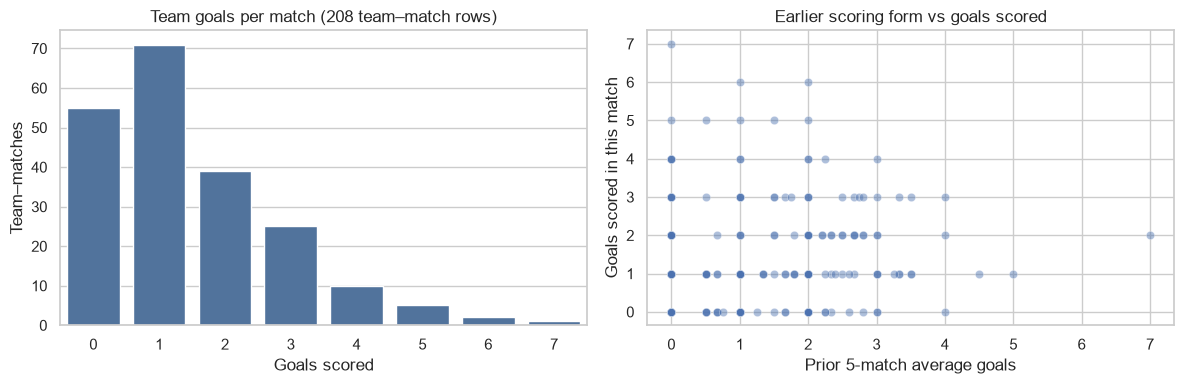

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=team_data, x="goals_scored", ax=axes[0], color="#4472A9")
axes[0].set(title="Team goals per match (208 team–match rows)", xlabel="Goals scored", ylabel="Team–matches")
sns.scatterplot(data=team_data, x="team_goals_for_5", y="goals_scored", alpha=.45, ax=axes[1])
axes[1].set(title="Earlier scoring form vs goals scored", xlabel="Prior 5-match average goals", ylabel="Goals scored in this match")
plt.tight_layout()
plt.show()

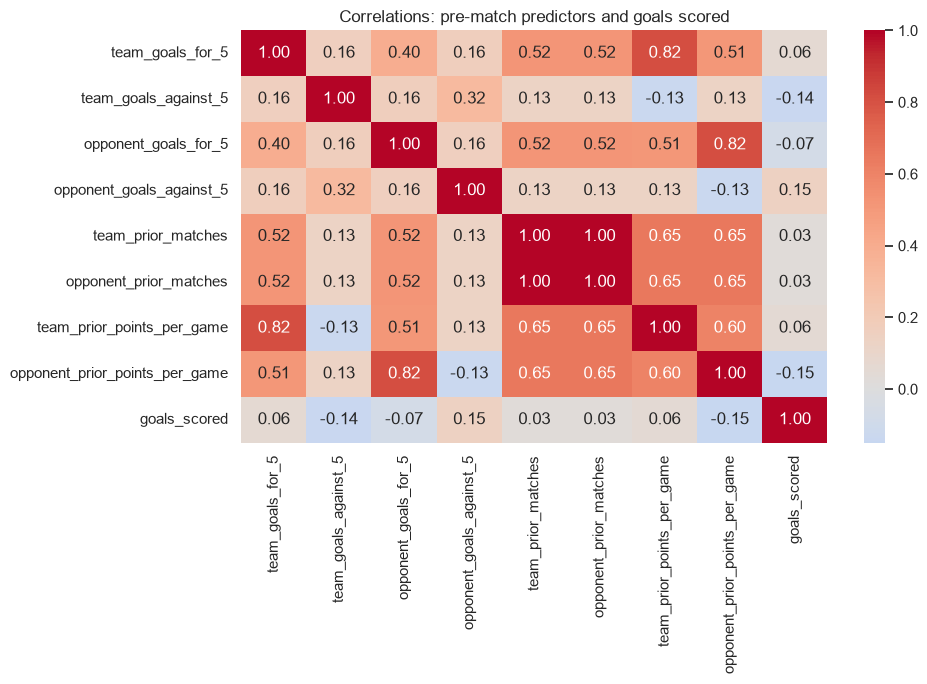

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(team_data[features + ["goals_scored"]].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlations: pre-match predictors and goals scored")
plt.tight_layout()
plt.show()

In [15]:
dates = sorted(team_data["date"].unique())
assert len(dates) >= 2, "Need at least two match dates"
cut = min(max(1, int(len(dates) * .8)), len(dates) - 1)
test_start = dates[cut]
train = team_data.loc[team_data["date"] < test_start].copy()
test = team_data.loc[team_data["date"] >= test_start].copy()
assert set(train.match_id).isdisjoint(test.match_id)
assert train.date.max() < test.date.min()
X_train, y_train = train[features], train["goals_scored"]
X_test, y_test = test[features], test["goals_scored"]
print(f"Train: {len(train)} team–matches ({train.match_id.nunique()} matches)")
print(f"Test: {len(test)} team–matches ({test.match_id.nunique()} matches)")
print("Test starts:", pd.Timestamp(test_start).date())

Train: 194 team–matches (97 matches)
Test: 14 team–matches (7 matches)
Test starts: 2026-07-10


In [17]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())

scores = pd.DataFrame({
    "MAE (goals)": [mean_absolute_error(y_test, pred), mean_absolute_error(y_test, baseline)],
    "RMSE (goals)": [np.sqrt(mean_squared_error(y_test, pred)), np.sqrt(mean_squared_error(y_test, baseline))],
    "R²": [r2_score(y_test, pred), r2_score(y_test, baseline)],
}, index=["Linear regression", "Training-mean baseline"])
display(scores.round(3))
display(pd.Series(model.coef_, index=features, name="coefficient").round(3))
print("Intercept:", round(model.intercept_, 3))

,MAE (goals),RMSE (goals),R²
Linear regression,1.067,1.604,-0.069
Training-mean baseline,1.143,1.603,-0.068


team_goals_for_5                  0.274
team_goals_against_5             -0.281
opponent_goals_for_5              0.159
opponent_goals_against_5          0.152
team_prior_matches                0.033
opponent_prior_matches            0.033
team_prior_points_per_game       -0.155
opponent_prior_points_per_game   -0.414
Name: coefficient, dtype: float64

Intercept: 1.599
Reminder: ordinary linear regression can predict negative or fractional goals;
evaluate its raw predictions before any optional rounding/clipping.


In [18]:
results = test[["match_id", "date", "team", "opponent"]].copy()
results["actual_goals"] = y_test.to_numpy()
results["predicted_goals"] = pred
results["error"] = results["actual_goals"] - results["predicted_goals"]
results["absolute_error"] = results["error"].abs()
display(results.sort_values("absolute_error", ascending=False).head(12).round(2))

C:\Users\supri\AppData\Local\Temp\ipykernel_5632\1004009787.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.sort_values("absolute_error", ascending=False).head(12).round(2))


,match_id,date,team,opponent,actual_goals,predicted_goals,error,absolute_error
204,103,2026-07-18,England,France,6,1.26,4.74,4.74
205,103,2026-07-18,France,England,4,1.59,2.41,2.41
198,100,2026-07-12,Argentina,Switzerland,3,1.42,1.58,1.58
200,101,2026-07-14,France,Spain,0,1.46,-1.46,1.46
206,104,2026-07-19,Argentina,Spain,0,1.16,-1.16,1.16
202,102,2026-07-15,Argentina,England,2,1.26,0.74,0.74
201,101,2026-07-14,Spain,France,2,1.33,0.67,0.67
196,99,2026-07-11,England,Norway,2,1.51,0.49,0.49
207,104,2026-07-19,Spain,Argentina,1,1.49,-0.49,0.49
195,98,2026-07-10,Spain,Belgium,2,1.67,0.33,0.33


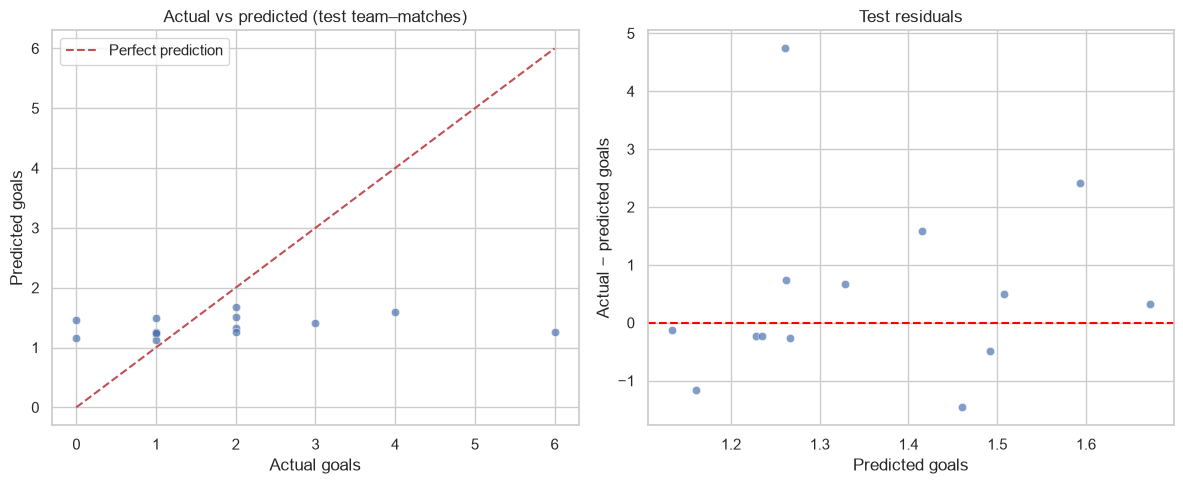

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=results, x="actual_goals", y="predicted_goals", alpha=.7, ax=axes[0])
lo = min(results.actual_goals.min(), results.predicted_goals.min())
hi = max(results.actual_goals.max(), results.predicted_goals.max())
axes[0].plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
axes[0].set(title="Actual vs predicted (test team–matches)", xlabel="Actual goals", ylabel="Predicted goals")
axes[0].legend()
sns.scatterplot(data=results, x="predicted_goals", y="error", alpha=.7, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Test residuals", xlabel="Predicted goals", ylabel="Actual − predicted goals")
plt.tight_layout()
plt.show()